# UTS Deep Learning: Evaluasi & Eksperimen Perbaikan (Anggota 4)
**Klasifikasi Jenis Sampah Berbasis Citra Menggunakan CNN dengan Data Augmentation dan Teknik Regularisasi**

```
My Drive/
└── deep_learning/
    ├── CNN_Sampah.py                (dari Anggota 3)
    ├── evaluasi_model.py            (Anggota 4)
    ├── eksperimen_perbaikan.py      (Anggota 4)
    ├── datasett_preprocessed.zip    (hasil Anggota 2, berbentuk ZIP)
    └── cnn_training_output/         (dari Anggota 3)
        ├── best_cnn_sampah.keras
        └── training_log.csv
```

## Cara pakai
1. Menu **Runtime → Change runtime type → T4 GPU → Save**.
2. Jalankan sel **Langkah 1 sampai 4** secara berurutan (wajib setiap kali membuka notebook / setelah sesi terputus).
3. Jalankan eksperimen **satu sel per eksperimen**. Hasil tersimpan otomatis di `My Drive/UTS_DeepLearning/hasil_eksperimen/`.

> Jika sesi terputus saat eksperimen berjalan: jalankan ulang Langkah 1 sampai 4, lalu ulangi sel eksperimen yang terputus. Eksperimen yang sudah selesai tidak perlu diulang.

## Langkah 1: Cek GPU

In [1]:
import tensorflow as tf
gpu = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU:", gpu if gpu else "TIDAK ADA. Aktifkan di Runtime > Change runtime type > T4 GPU")
!nvidia-smi -L

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-172ead36-a65f-eff2-d881-f12f3c87e8ee)


## Langkah 2: Hubungkan Google Drive & cek file

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
DRIVE_DIR = Path("/content/drive/MyDrive/deep_learning")

wajib = [
    "CNN_Sampah.py",
    "evaluasi_model.py",
    "eksperimen_perbaikan.py",
    "datasett_preprocessed.zip",
    "cnn_training_output/best_cnn_sampah.keras",
    "cnn_training_output/training_log.csv",
]
kurang = [f for f in wajib if not (DRIVE_DIR / f).exists()]
for f in wajib:
    print(("OK      " if f not in kurang else "TIDAK ADA ") + f)
if kurang:
    raise FileNotFoundError(f"Upload dulu file berikut ke {DRIVE_DIR}: {kurang}")
print("\nSemua file lengkap.")

Mounted at /content/drive
OK      CNN_Sampah.py
OK      evaluasi_model.py
OK      eksperimen_perbaikan.py
OK      datasett_preprocessed.zip
OK      cnn_training_output/best_cnn_sampah.keras
OK      cnn_training_output/training_log.csv

Semua file lengkap.


## Langkah 3: Siapkan folder kerja
Dataset diekstrak ke disk lokal Colab (lebih cepat dibaca), sedangkan folder `hasil_eksperimen` dihubungkan ke Google Drive agar hasil tidak hilang.

In [9]:
import os, shutil, zipfile

PROJ = Path("/content/proj")
PROJ.mkdir(exist_ok=True)

# 1) salin skrip & output Anggota 3 (selalu disalin ulang agar versi terbaru dari Drive terpakai)
for f in ["CNN_Sampah.py", "evaluasi_model.py", "eksperimen_perbaikan.py"]:
    shutil.copy(DRIVE_DIR / f, PROJ / f)
shutil.copytree(DRIVE_DIR / "cnn_training_output", PROJ / "cnn_training_output", dirs_exist_ok=True)

# 2) ekstrak dataset (hanya jika belum)
DATA = PROJ / "datasett_preprocessed"
if not DATA.exists():
    tmp = Path("/content/_ekstrak")
    print("Mengekstrak dataset... (1-3 menit)")
    with zipfile.ZipFile(DRIVE_DIR / "datasett_preprocessed.zip") as z:
        z.extractall(tmp)
    # cari folder yang berisi folder-folder kelas (menangani ZIP bertingkat)
    kandidat = [p for p in [tmp, *tmp.rglob("*")] if p.is_dir()
                and sum(1 for c in p.iterdir() if c.is_dir()) >= 5
                and not any(c.is_file() for c in p.iterdir())]
    sumber = min(kandidat, key=lambda p: len(p.parts))
    shutil.move(str(sumber), str(DATA))
    shutil.rmtree(tmp, ignore_errors=True)

# 3) hasil_eksperimen -> Google Drive
HASIL_DRIVE = DRIVE_DIR / "hasil_eksperimen"
HASIL_DRIVE.mkdir(exist_ok=True)
link = PROJ / "hasil_eksperimen"
if not link.exists():
    os.symlink(HASIL_DRIVE, link)

os.chdir(PROJ)
print("Folder kerja :", PROJ)
print("Kelas        :", sorted(p.name for p in DATA.iterdir() if p.is_dir()))
print("Hasil disimpan ke:", HASIL_DRIVE)

Folder kerja : /content/proj
Kelas        : ['Food Organics', 'Miscellaneous Trash', 'Plastic', 'Textile Trash', 'Vegetation', 'cardboard', 'glass', 'metal', 'paper', 'trash']
Hasil disimpan ke: /content/drive/MyDrive/deep_learning/hasil_eksperimen


## Langkah 4: Verifikasi pembagian data
Pembagian train/val/test harus **sama persis** dengan saat Anggota 3 melatih baseline. Jika tidak sama, test set bisa berisi gambar training sehingga hasil evaluasi tidak valid.

In [10]:
import sys
sys.path.insert(0, str(PROJ))
import CNN_Sampah as base

# angka dari log training Anggota 3
DIHARAPKAN = {
    "cardboard": (398, 49, 51), "Food Organics": (328, 41, 42), "glass": (468, 58, 60),
    "metal": (453, 56, 58), "Miscellaneous Trash": (396, 49, 50), "paper": (555, 69, 70),
    "Plastic": (736, 92, 93), "Textile Trash": (254, 31, 33), "trash": (109, 13, 15),
    "Vegetation": (347, 43, 44),
}
tr, va, te, kelas = base.collect_splits(base.DATASET_DIR)
cocok = True
print(f"{'Kelas':22s}{'train':>7s}{'val':>6s}{'test':>6s}   status")
for i, k in enumerate(kelas):
    n = (sum(l == i for _, l in tr), sum(l == i for _, l in va), sum(l == i for _, l in te))
    ok = DIHARAPKAN.get(k) == n
    cocok &= ok
    print(f"{k:22s}{n[0]:7d}{n[1]:6d}{n[2]:6d}   {'OK' if ok else 'BERBEDA, harap: ' + str(DIHARAPKAN.get(k))}")
print("\nPEMBAGIAN DATA SAMA DENGAN BASELINE" if cocok else
      "\nPERINGATAN: pembagian data BERBEDA. Pastikan ZIP dataset sama dengan yang dipakai Anggota 3.")

Kelas                   train   val  test   status
cardboard                 398    49    51   OK
Food Organics             328    41    42   OK
glass                     468    58    60   OK
metal                     453    56    58   OK
Miscellaneous Trash       396    49    50   OK
paper                     555    69    70   OK
Plastic                   736    92    93   OK
Textile Trash             254    31    33   OK
trash                     109    13    15   OK
Vegetation                347    43    44   OK

PEMBAGIAN DATA SAMA DENGAN BASELINE


In [11]:
# Fungsi bantu untuk menampilkan gambar hasil di notebook
from IPython.display import Image, display, Markdown
def tampilkan(nama, files=("diagnosis_training.txt", "training_curves.png", "confusion_matrix.png",
                           "f1_per_kelas.png", "contoh_salah_klasifikasi.png", "gradcam.png")):
    folder = PROJ / "hasil_eksperimen" / nama
    display(Markdown(f"### Hasil: `{nama}`"))
    for f in files:
        p = folder / f
        if not p.exists():
            continue
        display(Markdown(f"**{f}**"))
        if p.suffix == ".png":
            display(Image(filename=str(p), width=1100))
        else:
            print(p.read_text(encoding="utf-8"))

---
## Bagian A: Evaluasi model baseline (Anggota 3)
Waktu: ± 1 menit.

In [12]:
!python evaluasi_model.py

W0000 00:00:1793240013.660317    6882 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.

[INFO] Model tidak bisa dibuka langsung (kemungkinan versi Keras berbeda):
       <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (l
[INFO] Membangun ulang arsitektur dari CNN_Sampah.build_cnn() dan memuat bobotnya...
[INFO] Bobot berhasil dimuat.


[E0_baseline] Prediksi validation set...
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step
[E0_baseline] Prediksi test set...
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step
W0000 00:00:1793240028.189668    6882 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugproto    
batch: 1
in_depths: 64
out_depths: 128
in: 56
in: 56
data_format: 1
filter: 3
filter: 3
filter: 64
dilation: 1
d

In [13]:
tampilkan("E0_baseline")
print(open("hasil_eksperimen/E0_baseline/akurasi_per_sumber.csv").read())

Output hidden; open in https://colab.research.google.com to view.

---
## Bagian B: Eksperimen perbaikan
### B0. Uji cepat (cek skrip berjalan, ± 3 menit)
Hasil uji cepat disimpan di folder berawalan `_uji_` dan **tidak** ikut tabel perbandingan.

In [14]:
!python eksperimen_perbaikan.py --exp E2 --uji-cepat


########################################################################
# EKSPERIMEN E2_mobilenetv2
# Transfer learning MobileNetV2 + augmentasi + regularisasi, fine-tuning 40 layer
########################################################################
W0000 00:00:1793240096.199846    7422 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├──────────────

### B1. E2: Transfer learning MobileNetV2 + fine-tuning
Eksperimen utama (perkiraan dengan GPU T4: ± 10–25 menit).

In [15]:
!python eksperimen_perbaikan.py --exp E2


########################################################################
# EKSPERIMEN E2_mobilenetv2
# Transfer learning MobileNetV2 + augmentasi + regularisasi, fine-tuning 40 layer
########################################################################
W0000 00:00:1793240237.478279    8617 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼────

In [16]:
tampilkan("E2_mobilenetv2")

Output hidden; open in https://colab.research.google.com to view.

### B2. Studi ablasi: pengaruh augmentasi & regularisasi
Satu sel per eksperimen agar aman jika sesi terputus (perkiraan ± 5–10 menit per sel).

In [17]:
!python eksperimen_perbaikan.py --exp A1


########################################################################
# EKSPERIMEN A1_tanpa_aug_tanpa_reg
# Ablasi: MobileNetV2 beku, tanpa augmentasi, tanpa regularisasi
########################################################################
W0000 00:00:1793242239.783787   18208 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

In [18]:
!python eksperimen_perbaikan.py --exp A2


########################################################################
# EKSPERIMEN A2_aug_saja
# Ablasi: MobileNetV2 beku, augmentasi saja
########################################################################
W0000 00:00:1793242397.528990   19390 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224      

In [19]:
!python eksperimen_perbaikan.py --exp A3


########################################################################
# EKSPERIMEN A3_reg_saja
# Ablasi: MobileNetV2 beku, regularisasi saja
########################################################################
W0000 00:00:1793243450.002612   24450 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224    

In [20]:
!python eksperimen_perbaikan.py --exp A4


########################################################################
# EKSPERIMEN A4_aug_dan_reg
# Ablasi: MobileNetV2 beku, augmentasi + regularisasi
########################################################################
W0000 00:00:1793244041.656878   27537 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1

### Hasil: `A1_tanpa_aug_tanpa_reg`

**training_curves.png**

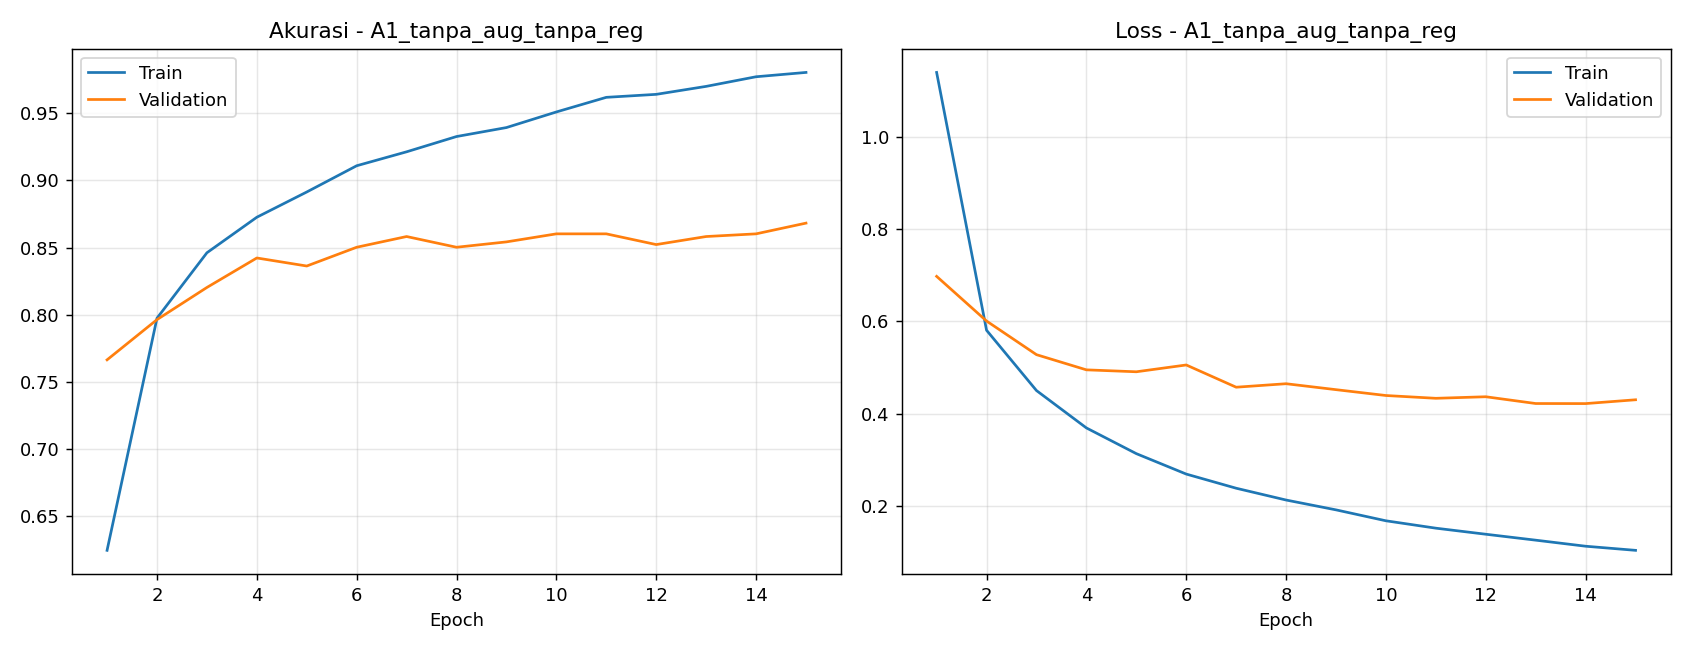

**confusion_matrix.png**

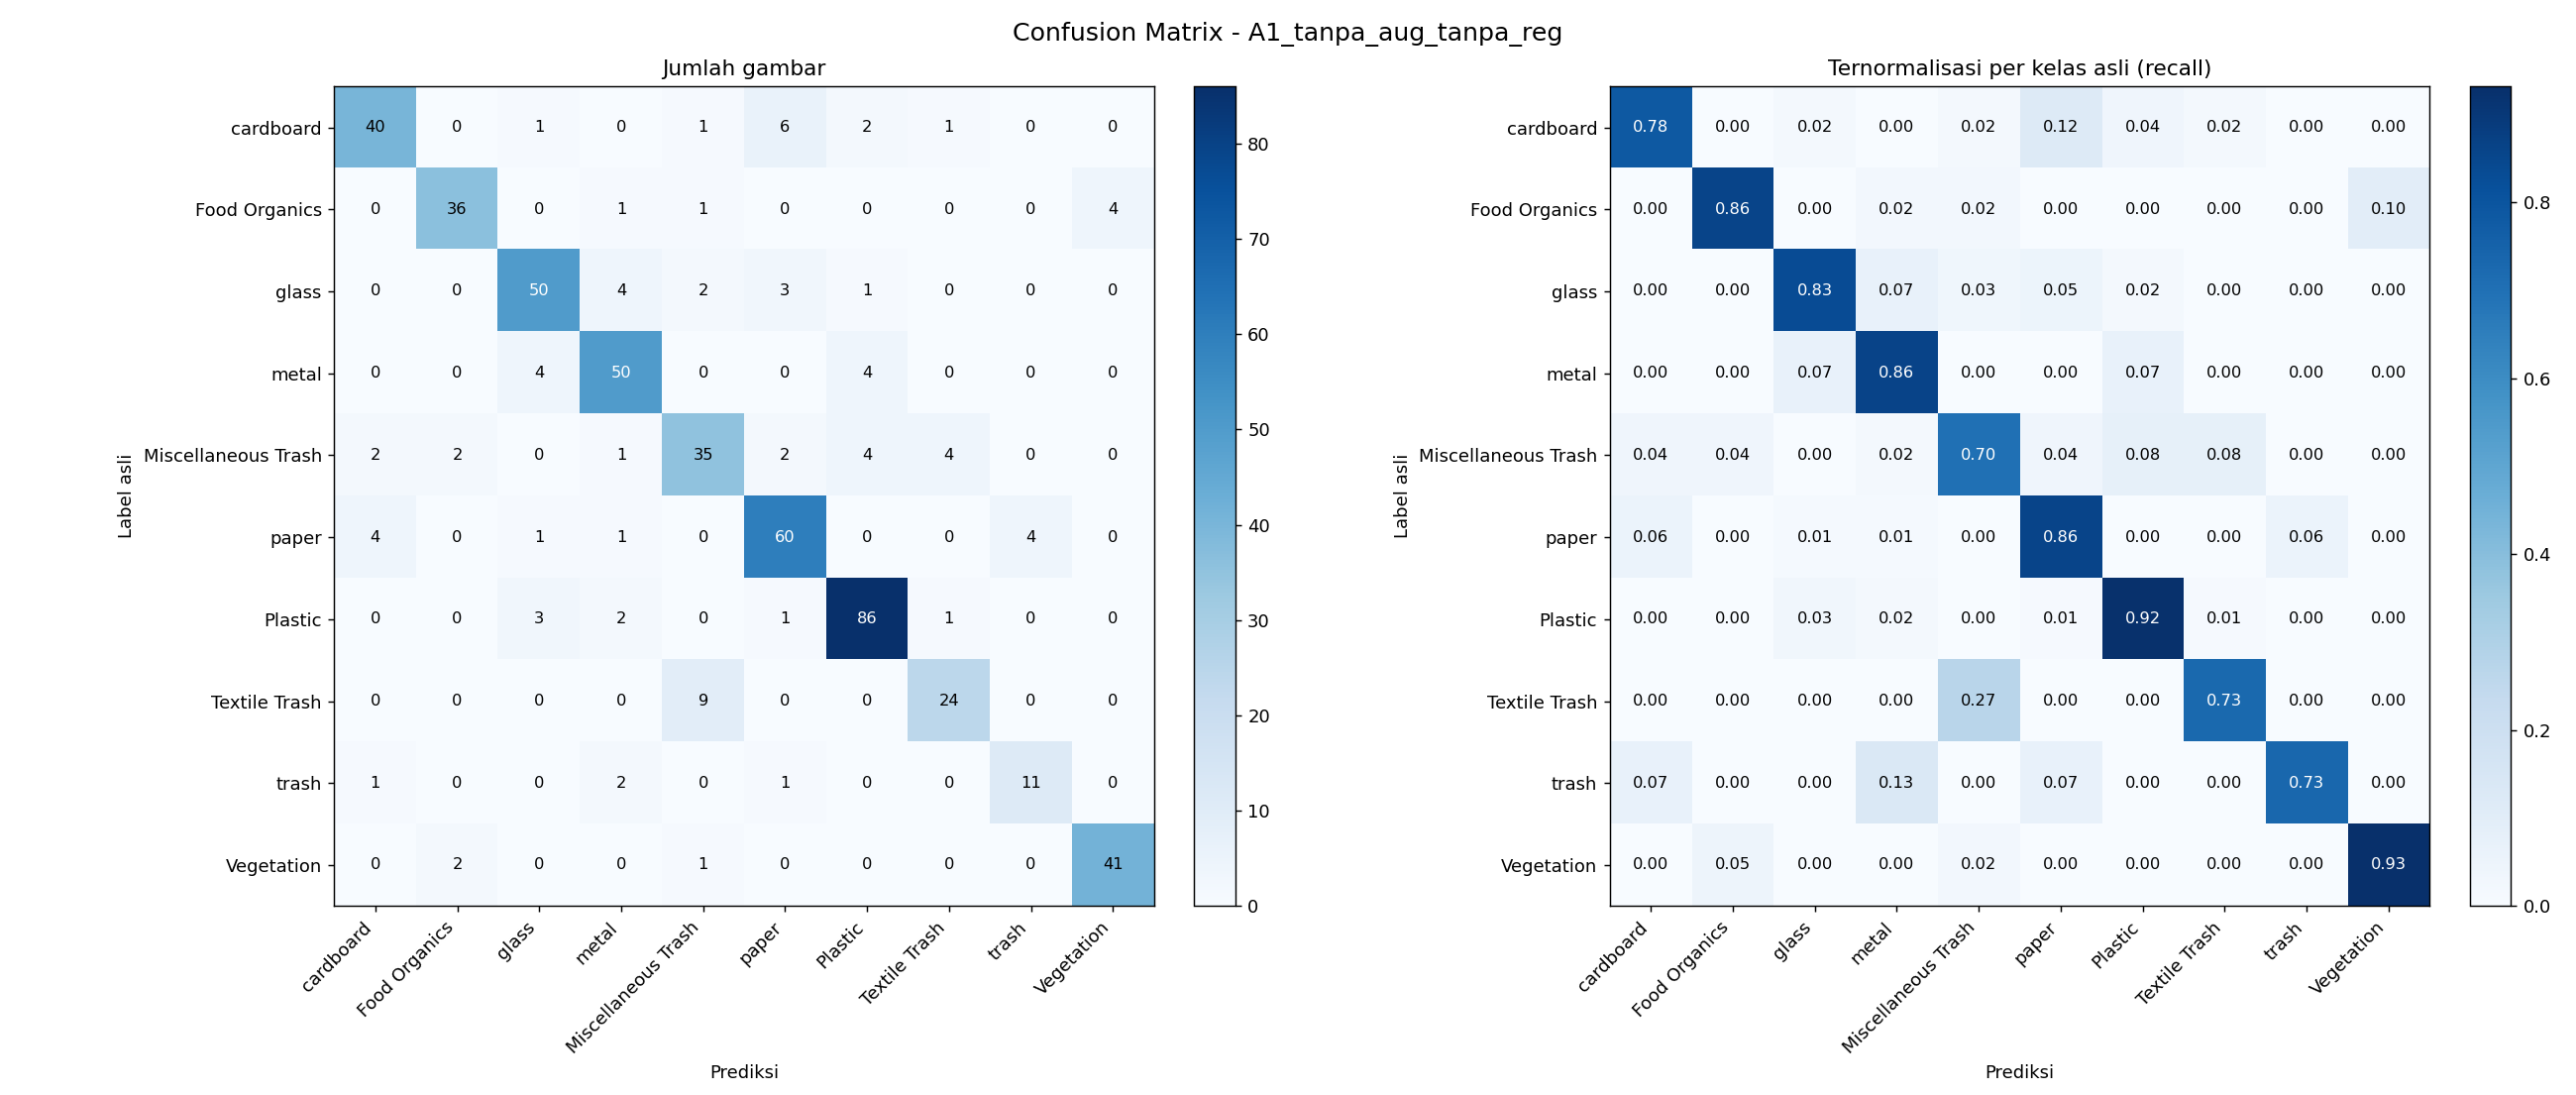

### Hasil: `A2_aug_saja`

**training_curves.png**

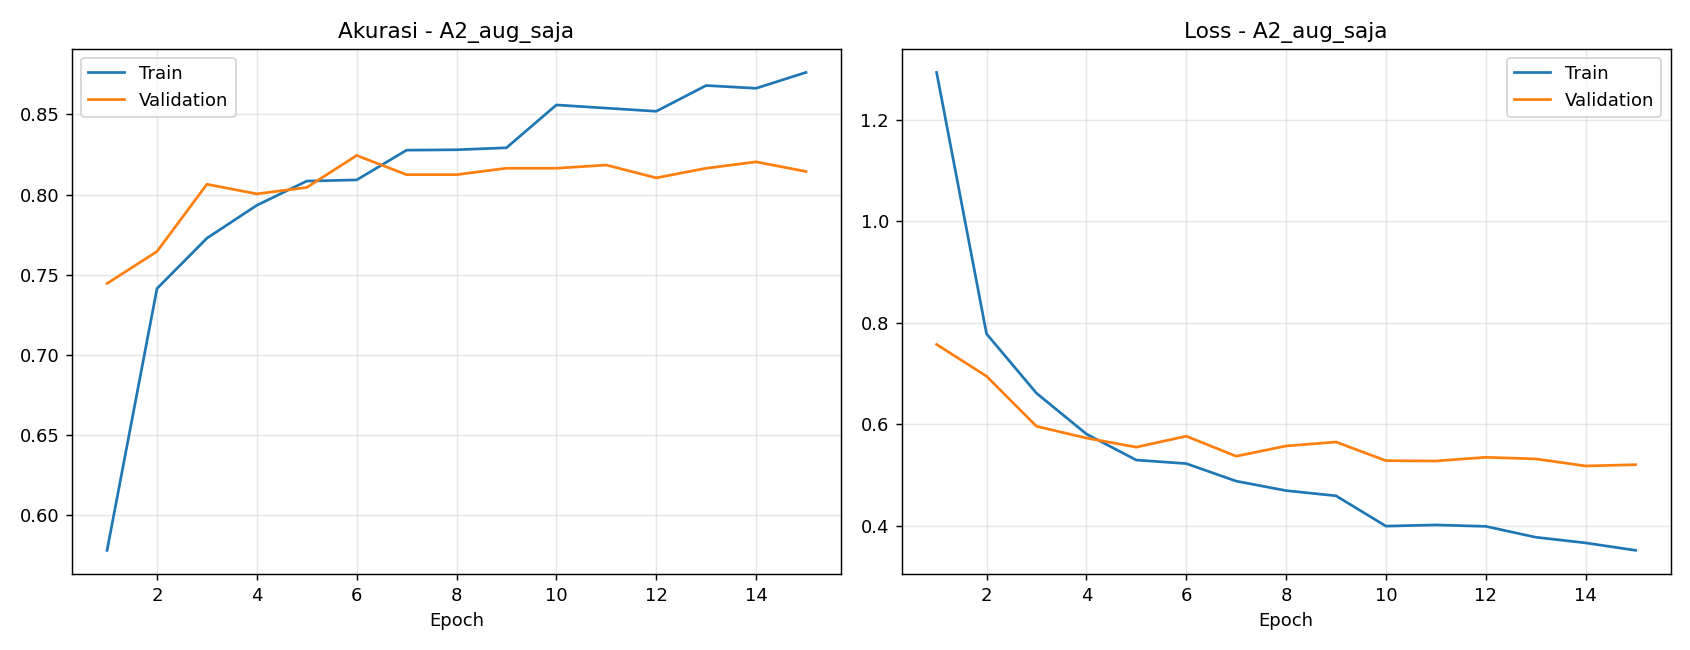

**confusion_matrix.png**

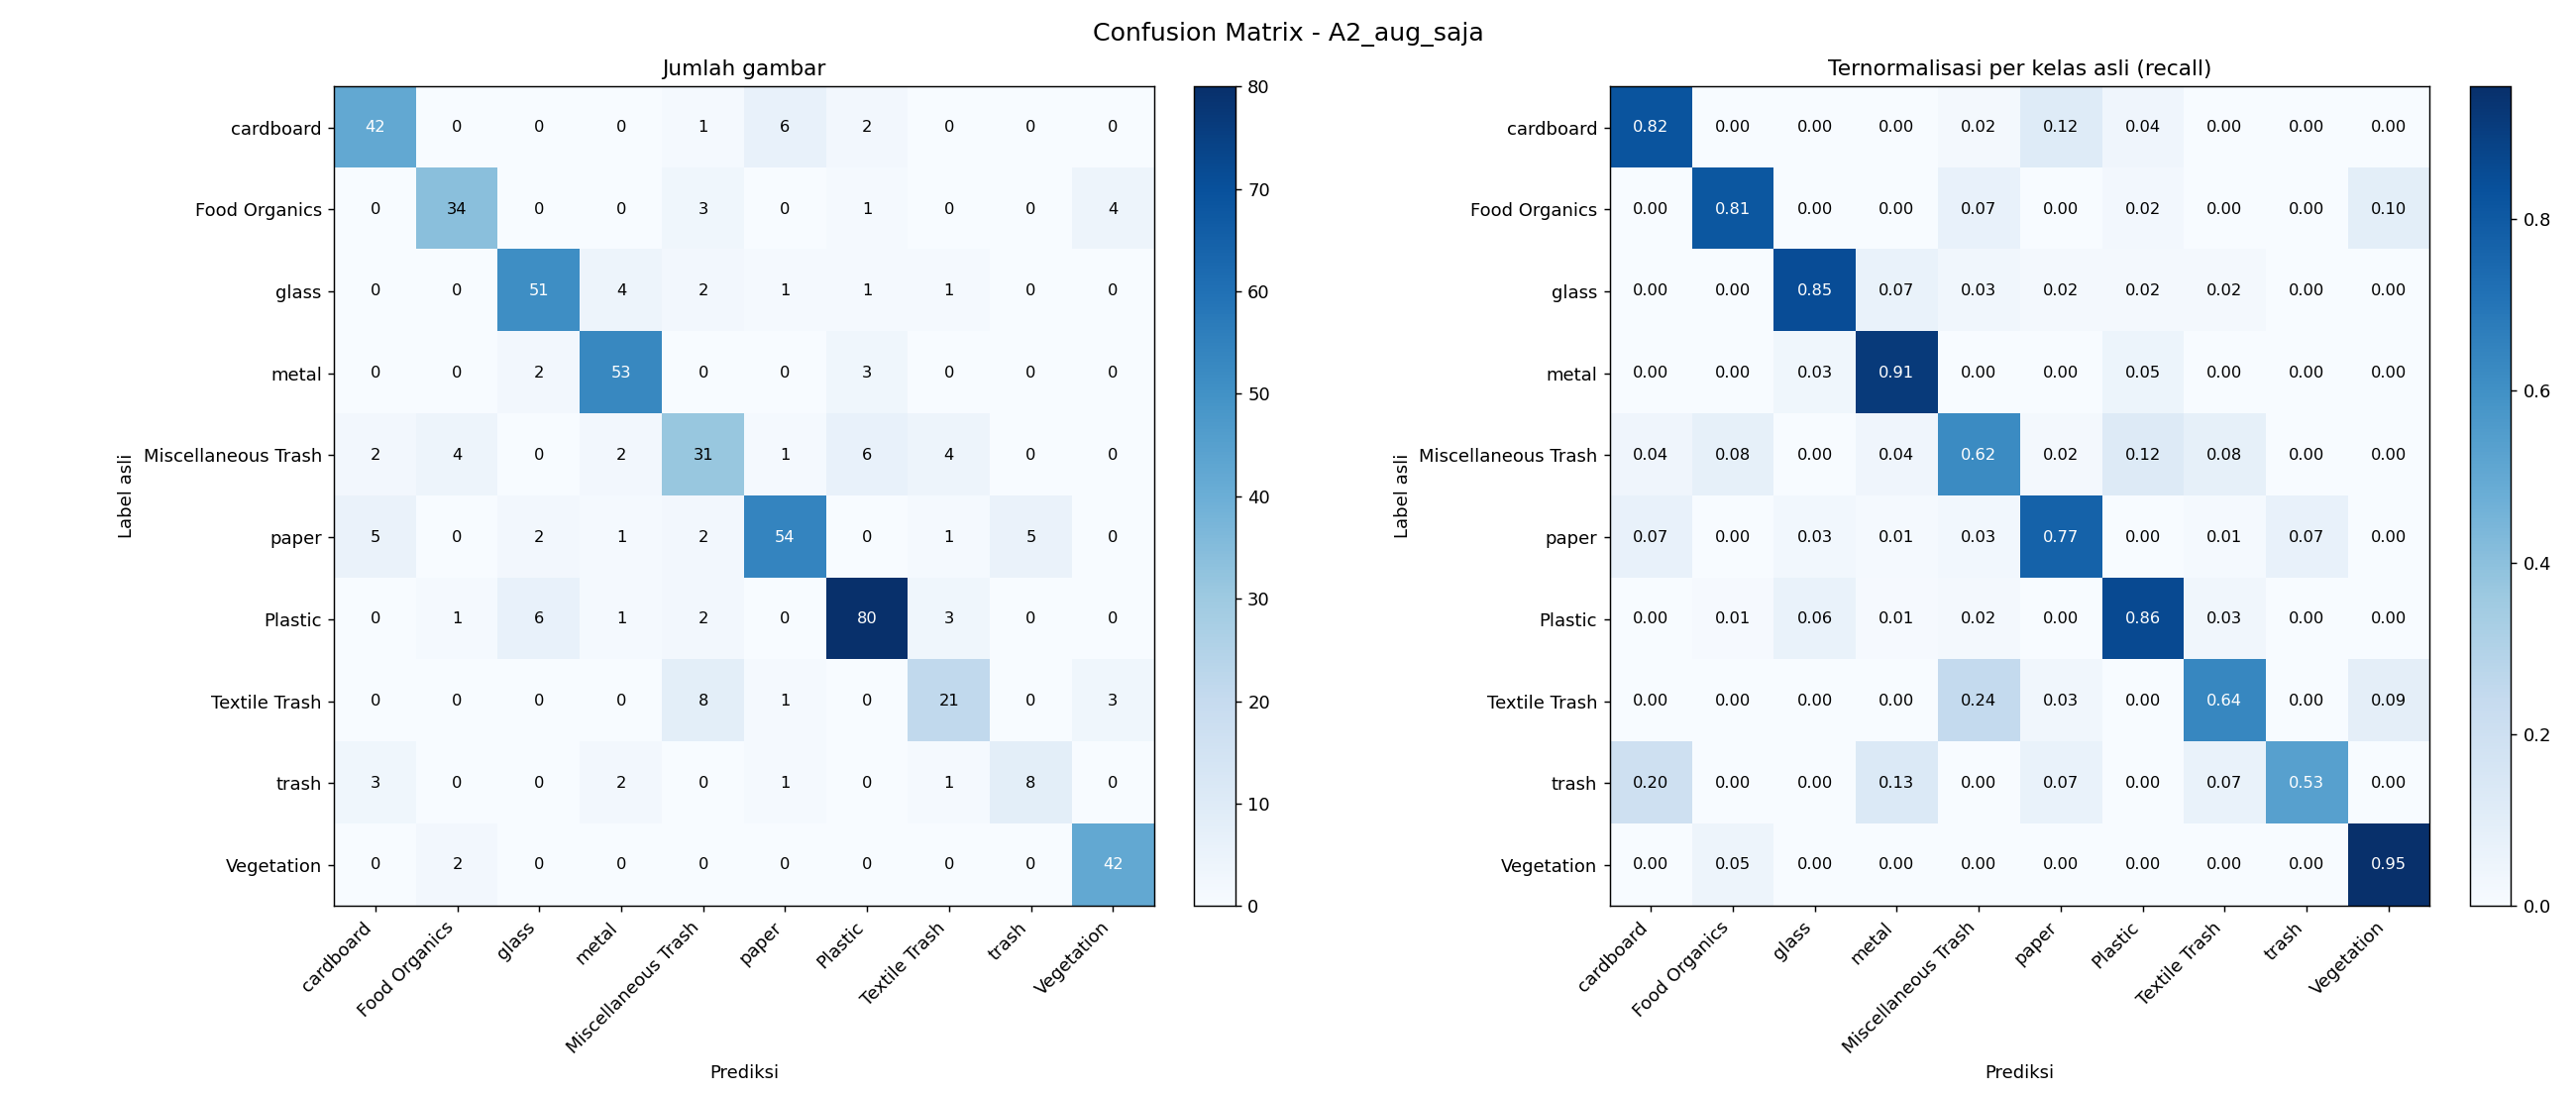

### Hasil: `A3_reg_saja`

**training_curves.png**

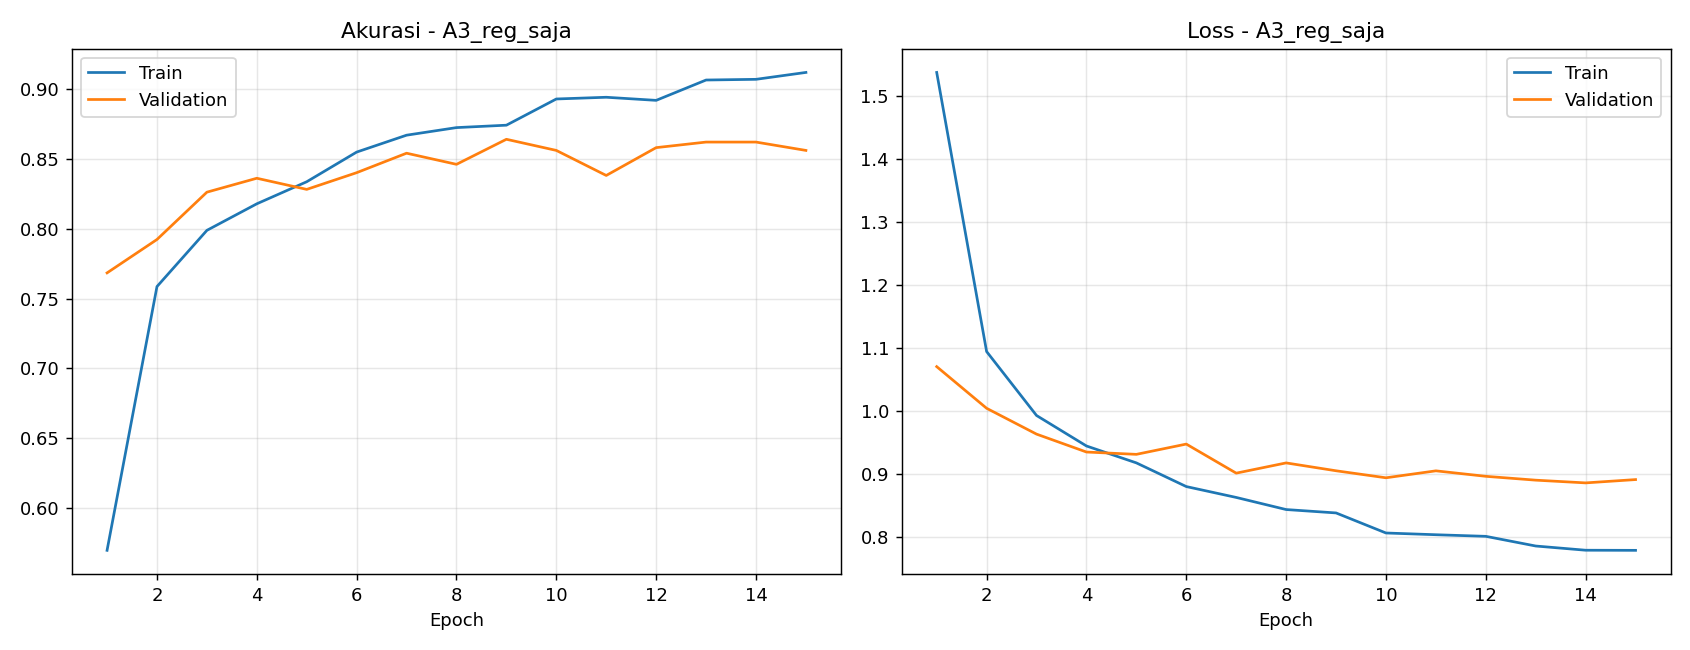

**confusion_matrix.png**

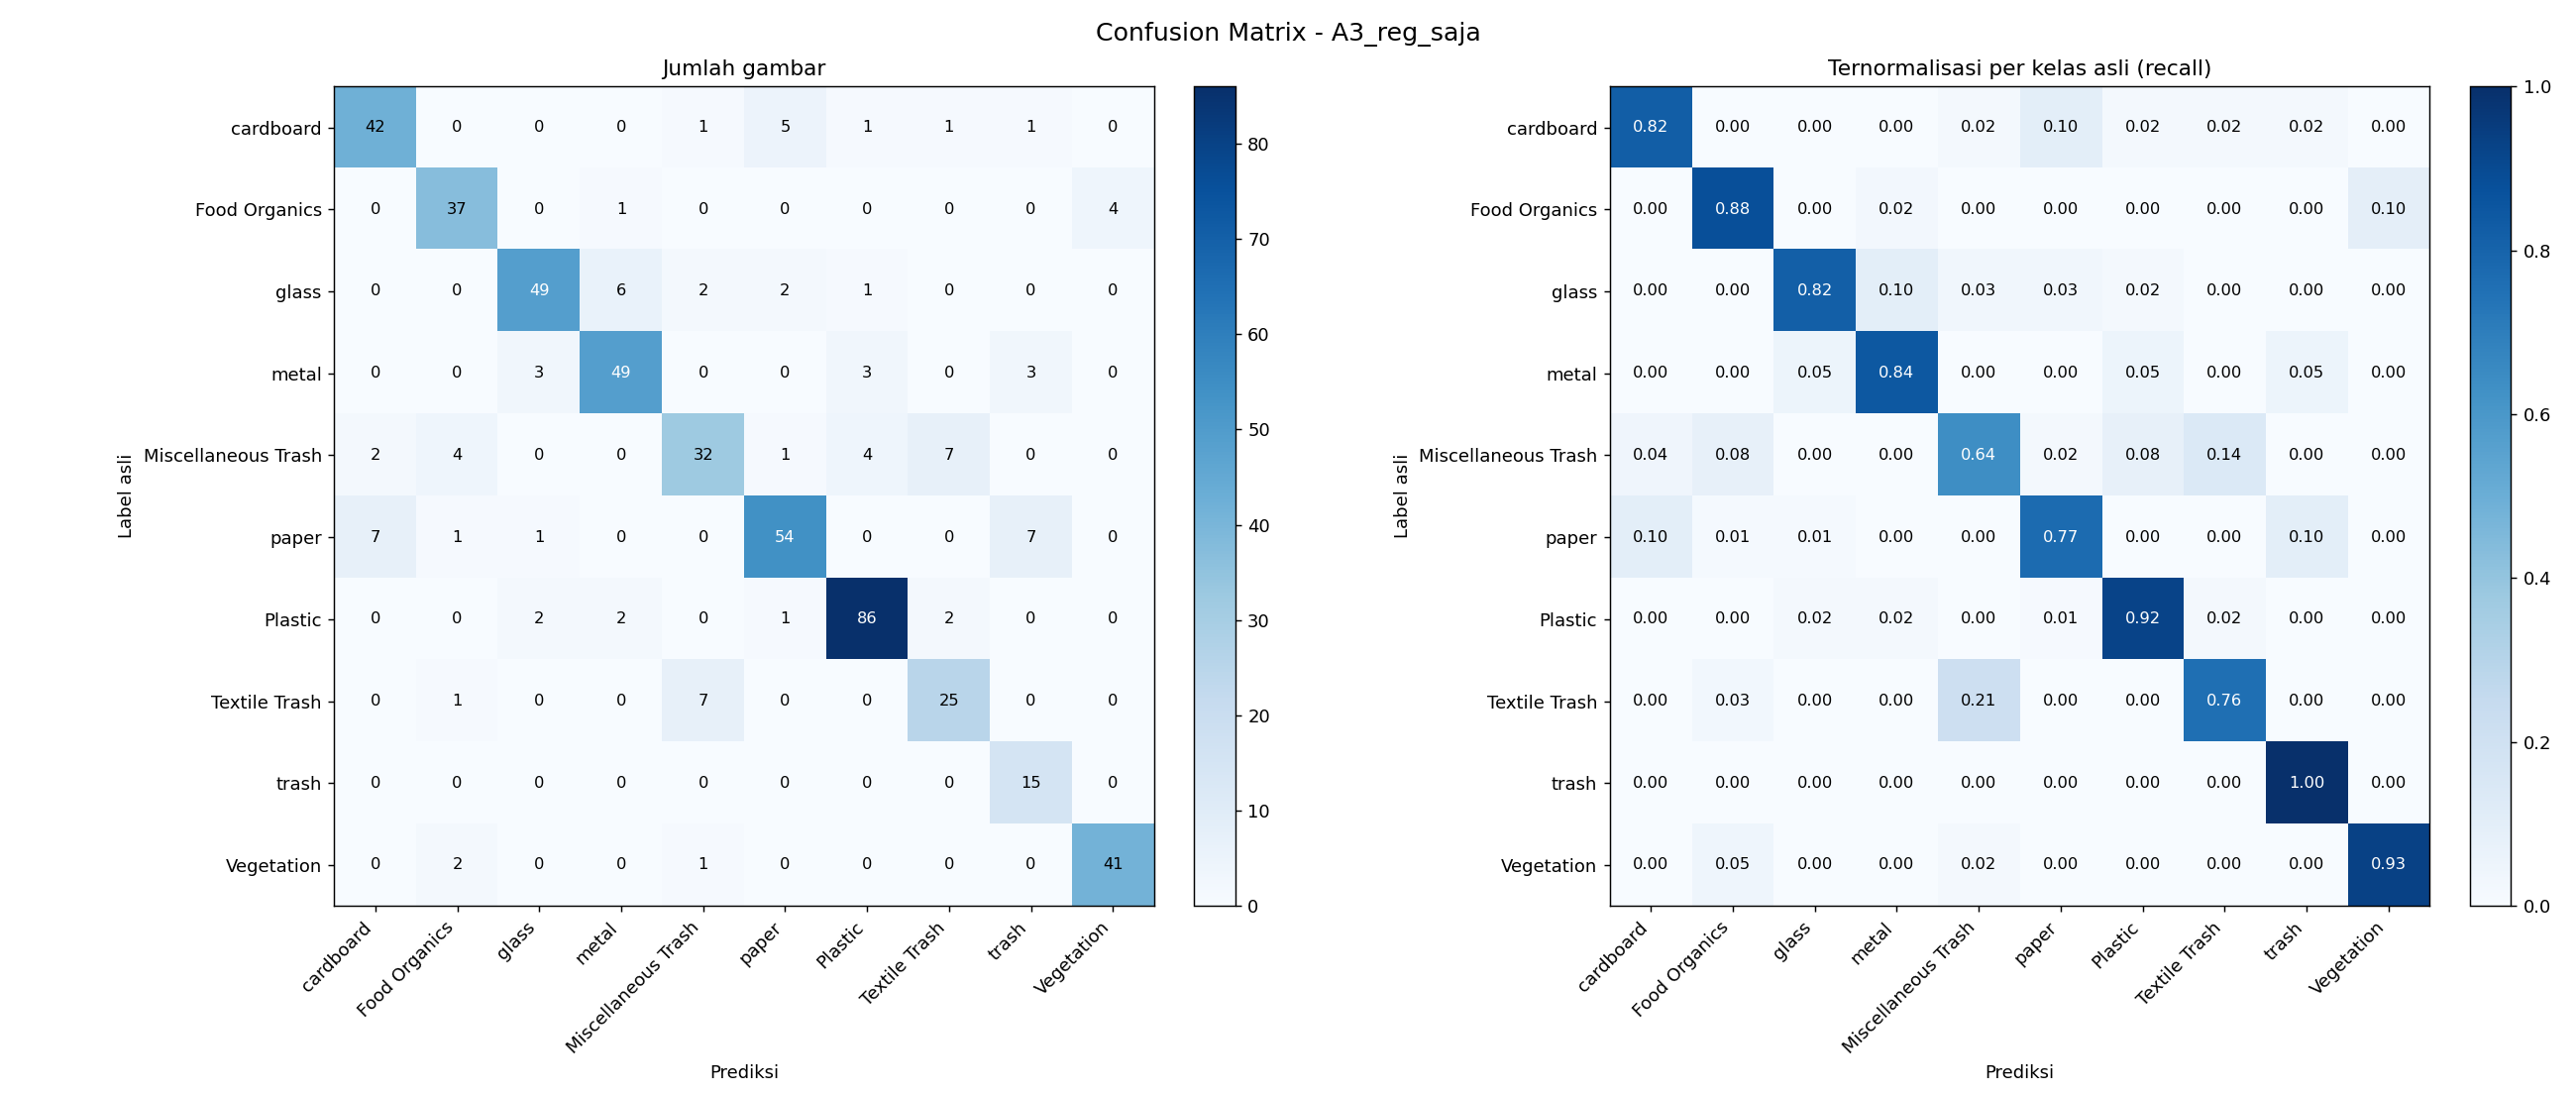

### Hasil: `A4_aug_dan_reg`

**training_curves.png**

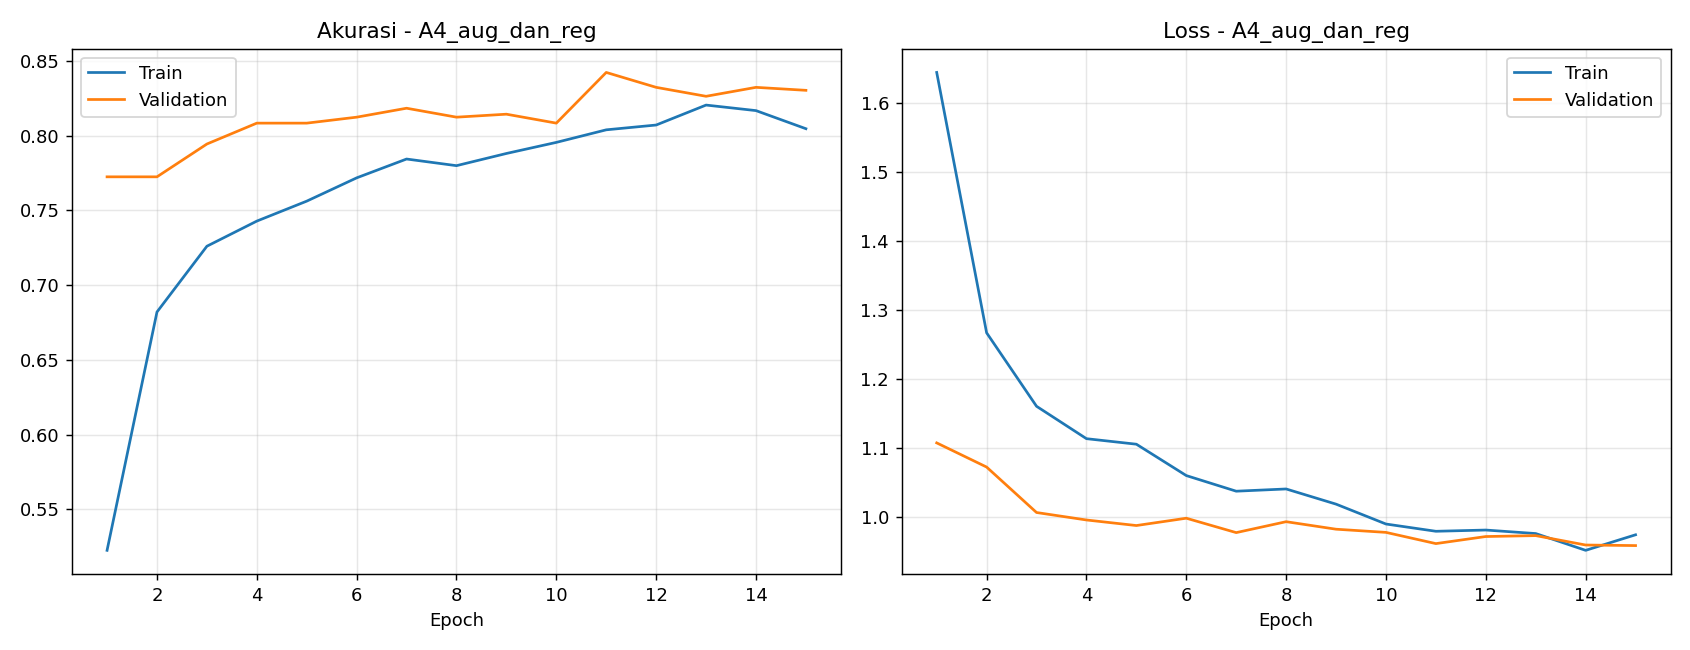

**confusion_matrix.png**

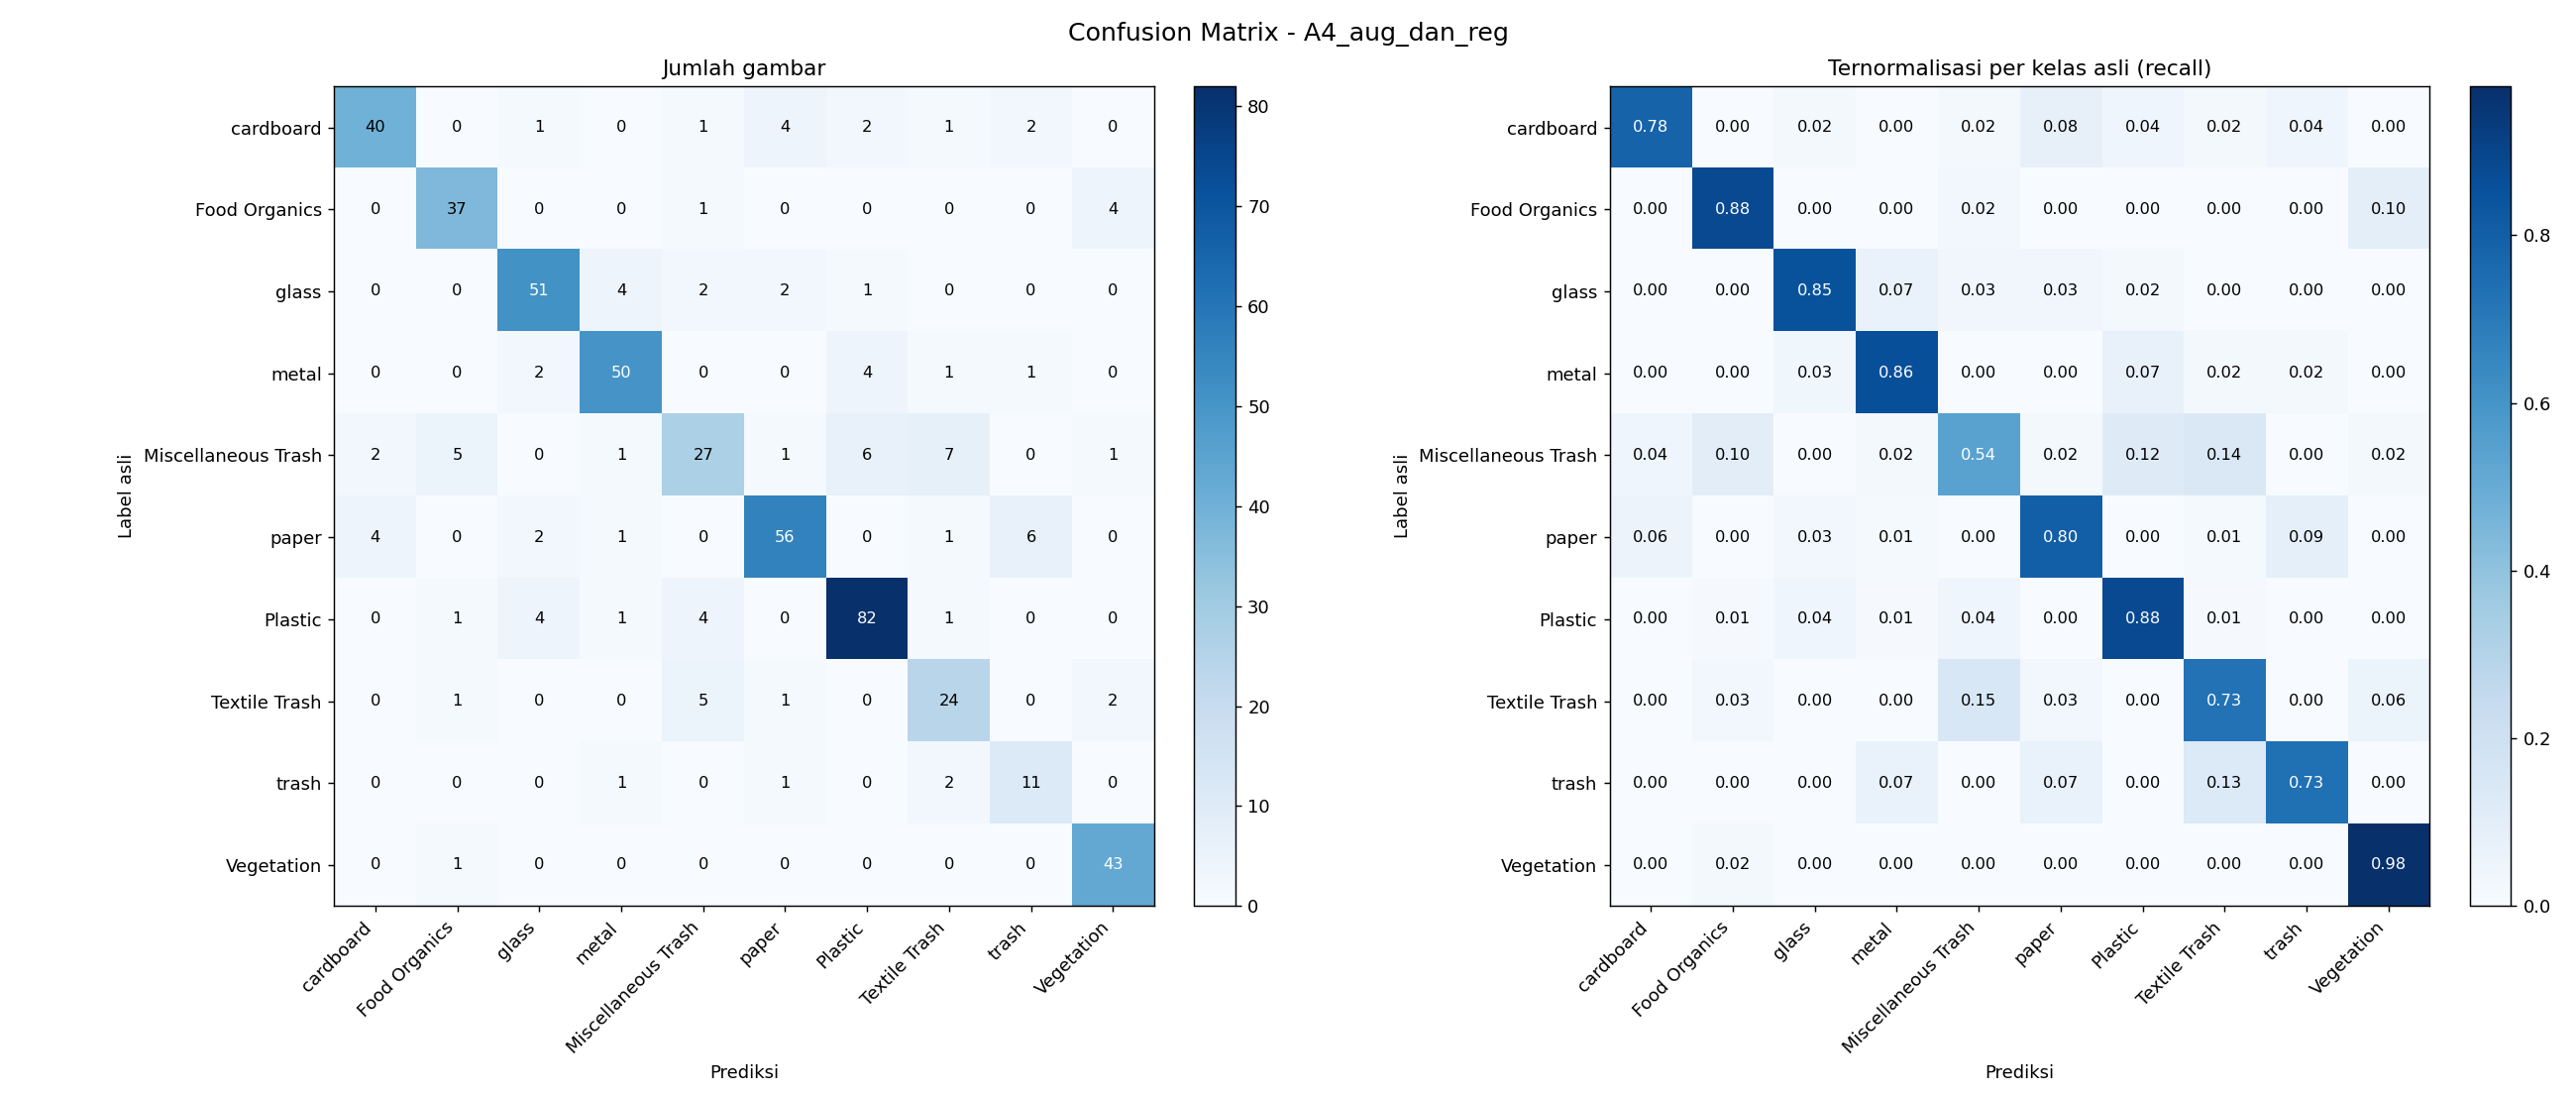

In [21]:
for n in ["A1_tanpa_aug_tanpa_reg", "A2_aug_saja", "A3_reg_saja", "A4_aug_dan_reg"]:
    tampilkan(n, files=("training_curves.png", "confusion_matrix.png"))

### B3. E1: CNN baseline yang distabilkan (dari nol)
Arsitektur sama dengan Anggota 3, training diperbaiki. Paling lama (perkiraan dengan GPU: ± 30–60 menit).

In [25]:
!python eksperimen_perbaikan.py --exp E1


########################################################################
# EKSPERIMEN E1_cnn_stabil
# CNN baseline + AdamW, warmup-cosine LR 5e-4, BN momentum 0.9, label smoothing 0.1, augmentasi kuat
########################################################################
W0000 00:00:1793246288.357898   37749 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "cnn_sampah_stabil"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────

In [26]:
tampilkan("E1_cnn_stabil")

Output hidden; open in https://colab.research.google.com to view.

---
## Bagian C: Ringkasan perbandingan (untuk laporan)
Menghasilkan `perbandingan_eksperimen.md` (tabel siap tempel), `perbandingan_eksperimen.csv`, dan dua grafik perbandingan.

In [27]:
!python eksperimen_perbaikan.py --ringkasan

| Eksperimen | Akurasi test | Macro F1 | Top-3 | Δ akurasi vs baseline | Keterangan |
|---|---|---|---|---|---|
| A1_tanpa_aug_tanpa_reg | 0.8391 | 0.8243 | 0.9787 | +28.5 poin | Ablasi: MobileNetV2 beku, tanpa augmentasi, tanpa regularisasi |
| A2_aug_saja | 0.8062 | 0.7777 | 0.9767 | +25.2 poin | Ablasi: MobileNetV2 beku, augmentasi saja |
| A3_reg_saja | 0.8333 | 0.8175 | 0.9806 | +27.9 poin | Ablasi: MobileNetV2 beku, regularisasi saja |
| A4_aug_dan_reg | 0.8159 | 0.7919 | 0.9690 | +26.2 poin | Ablasi: MobileNetV2 beku, augmentasi + regularisasi |
| E0_baseline | 0.5543 | 0.5411 | 0.8818 | +0.0 poin | CNN 4 blok dari nol (model Anggota 3) |
| E1_cnn_stabil | 0.6609 | 0.6392 | 0.8779 | +10.7 poin | CNN baseline + AdamW, warmup-cosine LR 5e-4, BN momentum 0.9, label smoothing 0.1, augmentasi kuat |
| E2_mobilenetv2 | 0.8275 | 0.8111 | 0.9748 | +27.3 poin | Transfer learning MobileNetV2 + augmentasi + regularisasi, fine-tuning 40 layer |

Ringkasan disimpan di: /content/proj/hasil_ek

| Eksperimen | Akurasi test | Macro F1 | Top-3 | Δ akurasi vs baseline | Keterangan |
|---|---|---|---|---|---|
| A1_tanpa_aug_tanpa_reg | 0.8391 | 0.8243 | 0.9787 | +28.5 poin | Ablasi: MobileNetV2 beku, tanpa augmentasi, tanpa regularisasi |
| A2_aug_saja | 0.8062 | 0.7777 | 0.9767 | +25.2 poin | Ablasi: MobileNetV2 beku, augmentasi saja |
| A3_reg_saja | 0.8333 | 0.8175 | 0.9806 | +27.9 poin | Ablasi: MobileNetV2 beku, regularisasi saja |
| A4_aug_dan_reg | 0.8159 | 0.7919 | 0.9690 | +26.2 poin | Ablasi: MobileNetV2 beku, augmentasi + regularisasi |
| E0_baseline | 0.5543 | 0.5411 | 0.8818 | +0.0 poin | CNN 4 blok dari nol (model Anggota 3) |
| E1_cnn_stabil | 0.6609 | 0.6392 | 0.8779 | +10.7 poin | CNN baseline + AdamW, warmup-cosine LR 5e-4, BN momentum 0.9, label smoothing 0.1, augmentasi kuat |
| E2_mobilenetv2 | 0.8275 | 0.8111 | 0.9748 | +27.3 poin | Transfer learning MobileNetV2 + augmentasi + regularisasi, fine-tuning 40 layer |

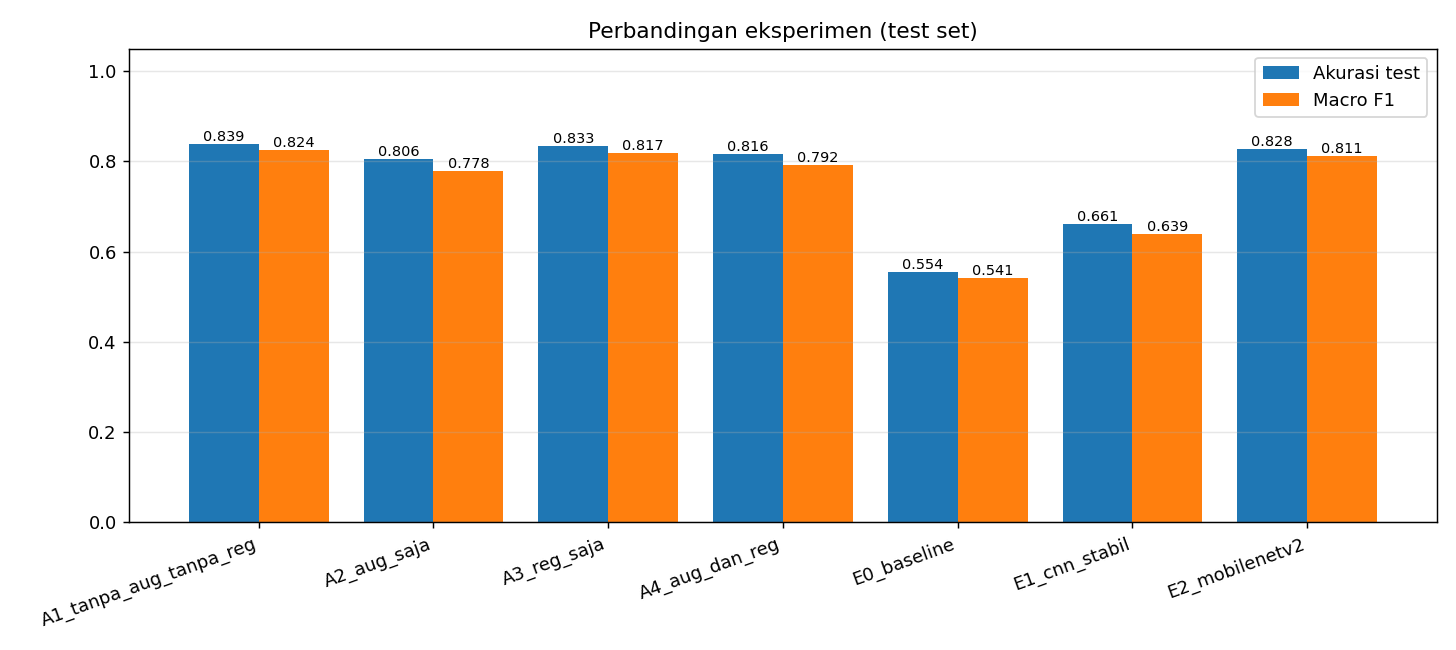

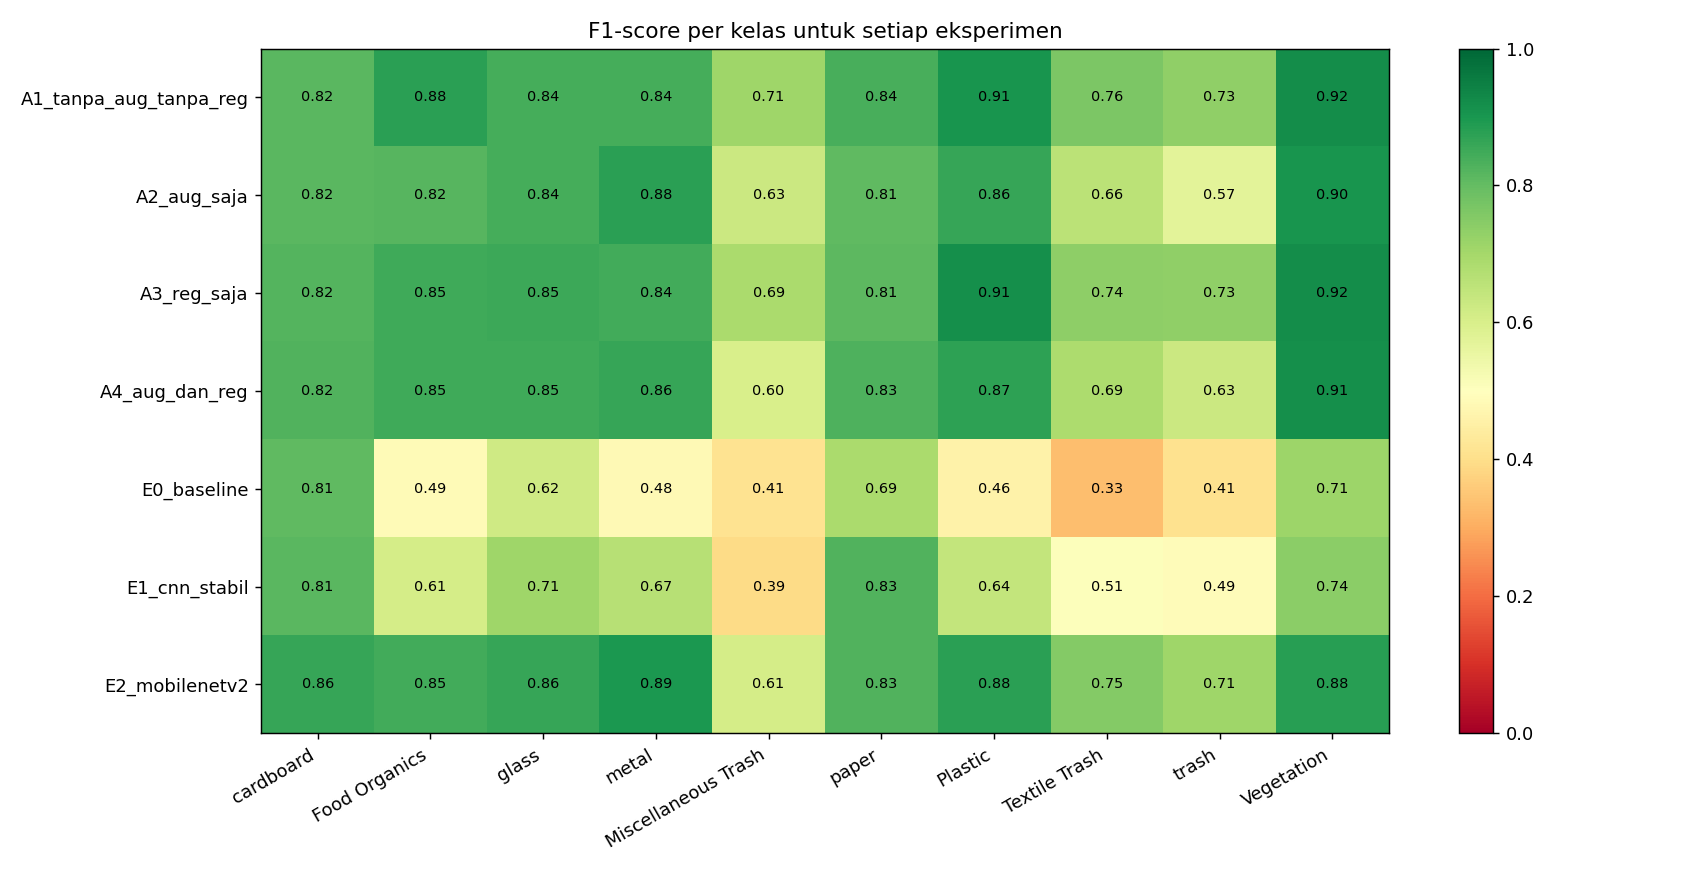

In [28]:
display(Markdown(open("hasil_eksperimen/perbandingan_eksperimen.md", encoding="utf-8").read()))
display(Image(filename="hasil_eksperimen/perbandingan_eksperimen.png", width=1000))
display(Image(filename="hasil_eksperimen/f1_per_kelas_perbandingan.png", width=1100))

---
## (Opsional) Unduh semua hasil sebagai ZIP
Semua hasil sudah ada di Google Drive. Sel ini hanya untuk mengunduh satu file ZIP ke laptop.

In [29]:
shutil.make_archive("/content/hasil_eksperimen", "zip", root_dir=str(HASIL_DRIVE))
from google.colab import files
files.download("/content/hasil_eksperimen.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>